## Homework 3 - Analysis Using the $p$, $np$, $c$, and $u$ Control Charts
### Dr. Austin Brown
### Kennesaw State University

**DUE: October 30, 2026 via D2L**

## Instructions:

Ravi's Comics and Games is a local comic book and tabletop game shop that receives weekly new-release shipments from a regional distributor. Ravi's customers, especially the collectors chasing near-mint copies, have started complaining more often about comics arriving with scratched or folded covers, and Ravi has noticed it's starting to hurt sales of his higher-end back issues too. He's asked your quality control team to help him figure out how bad the problem really is, whether it's getting better or worse, and who -- the distributor, or his own shop -- is responsible.

Your team decides to look at this two different ways. First, every comic in a week's shipment gets a quick pass/fail condition check as staff unbox and shelve it (any visible scratch, crease, or fold on the cover marks it nonconforming). Because the number of comics in a shipment varies week to week depending on the new-release schedule, your team tracks both the **rate** of nonconforming comics (useful for spotting trends) and the **raw count** (useful when Ravi calls the distributor's account representative, who thinks in terms of "how many books," not percentages).

Second, your team recognizes that a single comic can have more than one distinct defect on it -- a scratch on the front cover **and** a folded corner on the back, for example -- so a simple pass/fail check doesn't capture the full severity of the damage. To get a fuller picture, staff also perform a more detailed defect count each week, counting every individual scratch, fold, or dent they find (not just how many comics have at least one). This detailed count is done on two separate parts of the shop: a **fixed** sample of 5 boxes pulled from the new-release shipment every week, and a **variable** number of already-shelved back-issue boxes, inspected whenever staff have the time.

## Key Specifications

| Quantity | Value |
|---|---|
| Nonconforming definition (Datasets A) | Any visible scratch, crease, or fold on the cover |
| Nonconformity definition (Datasets B & C) | Each individual scratch, fold, or dent found (a comic may have more than one) |
| Dataset A: Shipment Condition, Phase I weeks (m) | 25 weeks, variable shipment size |
| Dataset A: Shipment Condition, Phase II weeks (m) | 20 weeks, variable shipment size |
| Dataset B: New-Release Defect Counts, weeks (m) | 25 weeks, fixed sample of 5 boxes/week |
| Dataset C: Back-Issue Defect Counts, weeks (m) | 25 weeks, variable number of boxes/week |

## Define & Measure

### Q1: Briefly describe the purpose of this analysis

The purpose of this analysis is to see the extent of damage of the comic books. To see if the damage is getting worse or better, and identify if it is occurring at distribution or within the shop. I'll look at number of nonconforming comics and the total number of individual defects across the new shipments and inventory to assess damage, and see where it is occurring and identify if it is not so bad, getting better, or getting worse.

### Q2: Ravi's team is monitoring two distinct quality characteristics here: a pass/fail condition check, and a detailed defect count. For each, classify the type of attribute data being collected, and briefly explain how this differs from the continuous, normally-distributed data used in your previous two homeworks.

The pass/fail condition check will collect data binomial of conforming or non-conforming. The more detailed defect count will collect attribute data classified as Poisson based approach. The previous homeworks were using measured continuous and normally distributed data while this analysis uses discrete data of counts and proportions rather than the  continous measurements of filament diameter and volume of beer.

### Q3: For the pass/fail data (Dataset A), what practical factor determines whether you should build a $p$ chart or an $np$ chart? For the detailed defect-count data (Datasets B and C), what practical factor determines whether you should build a $c$ chart or a $u$ chart?

For the pass/fail of Dataset A we will use a p chart because the sample size varies. If the sample size is constant than a np chart is the better option. For the defect-count data of Datasets B and C for B we will use a c chart because the sample size will be constant and for Dataset C we will use a u chart because again the sample size varies.

## Analyze

### Q4: Read the Phase I Shipment Condition data (Dataset A) into R. Construct a Phase I $p$ chart. Does the chart show evidence of statistical control? If not, identify the out-of-control week(s) by number and provide a contextual explanation as to why these OOC point(s) may have been observed, omit them, and replot the chart until statistical control is observed.

In [5]:
# Set up and libarary installs
## Specify your GitHub username:
user_name <- "abarre71"

## Specify the repository:
repo_name <- "STAT-7110-Quality-Control"

## Set the web address to your forked repository:
repo_address <- paste0(
  "https://github.com/",
  user_name,
  "/",
  repo_name,
  ".git"
)

## Check to see if repo is already cloned to Colab, and if not, clone repo:
if (!dir.exists(repo_name)) {
  system(paste("git clone", repo_address))
} else {
  print("Repository already cloned to Colab.")
}

setwd("/content/STAT-7110-Quality-Control/Assignments/HW3")
getwd()

install.packages(c("readxl","tidyverse","qcc"))
library(readxl)
library(tidyverse)
library(qcc)

[1] "Repository already cloned to Colab."


[1] "/content/STAT-7110-Quality-Control/Assignments/HW3"

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Package 'qcc' version 2.7

Type 'citation("qcc")' for citing this R package in publications.



Rows: 25
Columns: 3
$ Week                <dbl> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15,…
$ TotalComics         <dbl> 194, 216, 149, 142, 124, 212, 144, 117, 187, 201, …
$ NumberNonconforming <dbl> 7, 8, 6, 8, 5, 17, 11, 2, 9, 8, 9, 11, 9, 74, 7, 6…


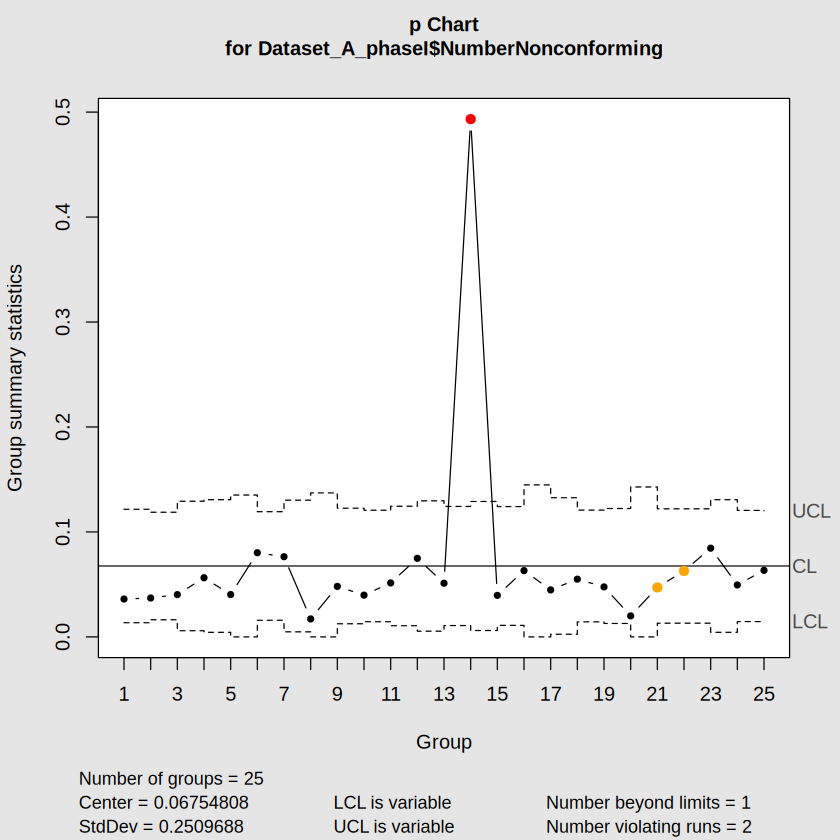

In [9]:
## Q4 Code ##
Dataset_A_phaseI<-read_xlsx("RavisComics_ShipmentCondition_PhaseI.xlsx")

glimpse(Dataset_A_phaseI)

pchart_A_PhaseI <- qcc(Dataset_A_phaseI$`NumberNonconforming`,type="p",
                sizes=Dataset_A_phaseI$`TotalComics`,
                plot=T)

In [10]:
pchart_A_PhaseI$violations

$beyond.limits
[1] 14

$violating.runs
[1] 21 22

We see that Week 14 is OOC point, this could be due to the shipment that week being improperly packaged by the distributor or bad handling of the shipment by the carrier. We will omit this week and replot.

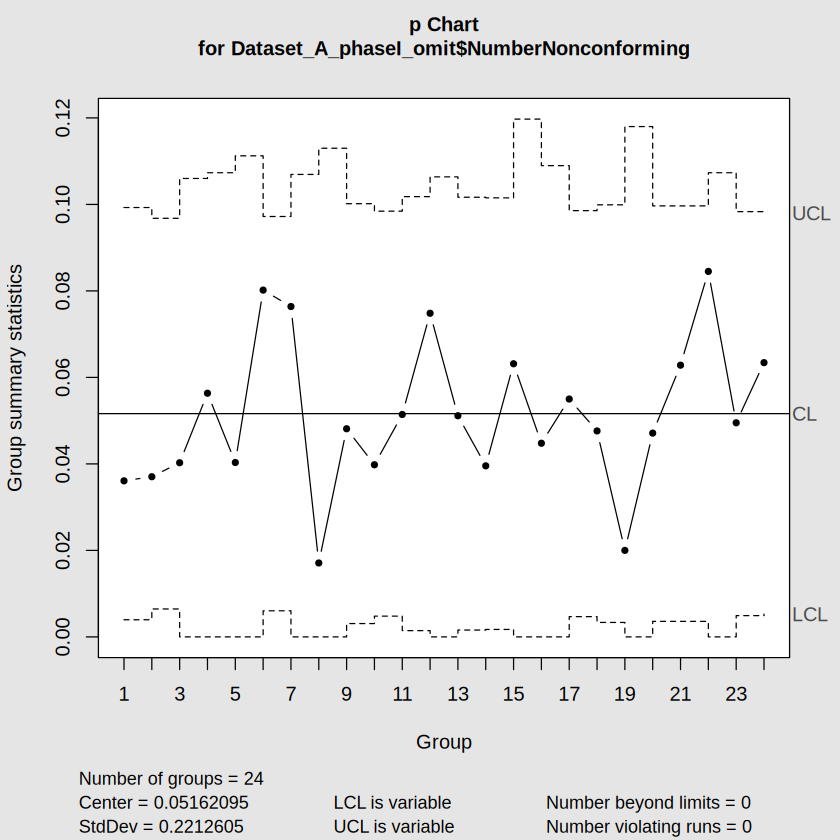

In [24]:
Dataset_A_phaseI_omit<-Dataset_A_phaseI[-14,]
pchart_A_PhaseI_IC <- qcc(Dataset_A_phaseI_omit$`NumberNonconforming`,type="p",
                sizes=Dataset_A_phaseI_omit$`TotalComics`,
                plot=T)

In [ ]:
We now see statistical control within our p chart.

### Q5: Repeat the analysis in Q4, this time constructing an $np$ chart on the same data. Do your conclusions about which week(s) are out of control change? Which chart do you think would be easier to explain to the distributor's account representative, and why?

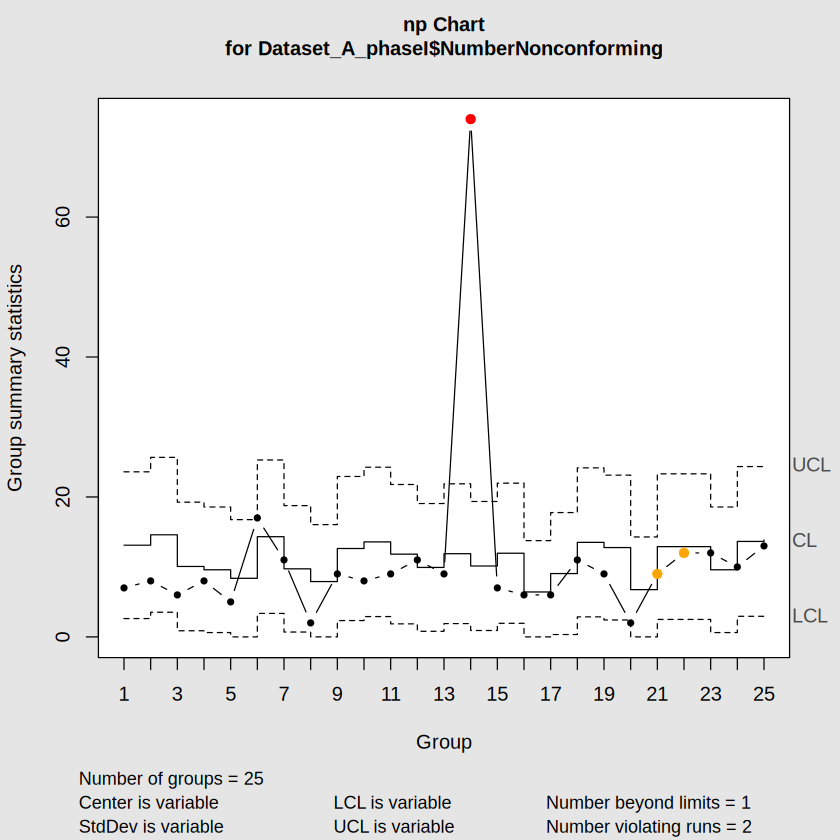

In [23]:
## Q5 Code ##
npchart_A_PhaseI <- qcc(Dataset_A_phaseI$`NumberNonconforming`,type="np",
                sizes=Dataset_A_phaseI$`TotalComics`,
                plot=T)

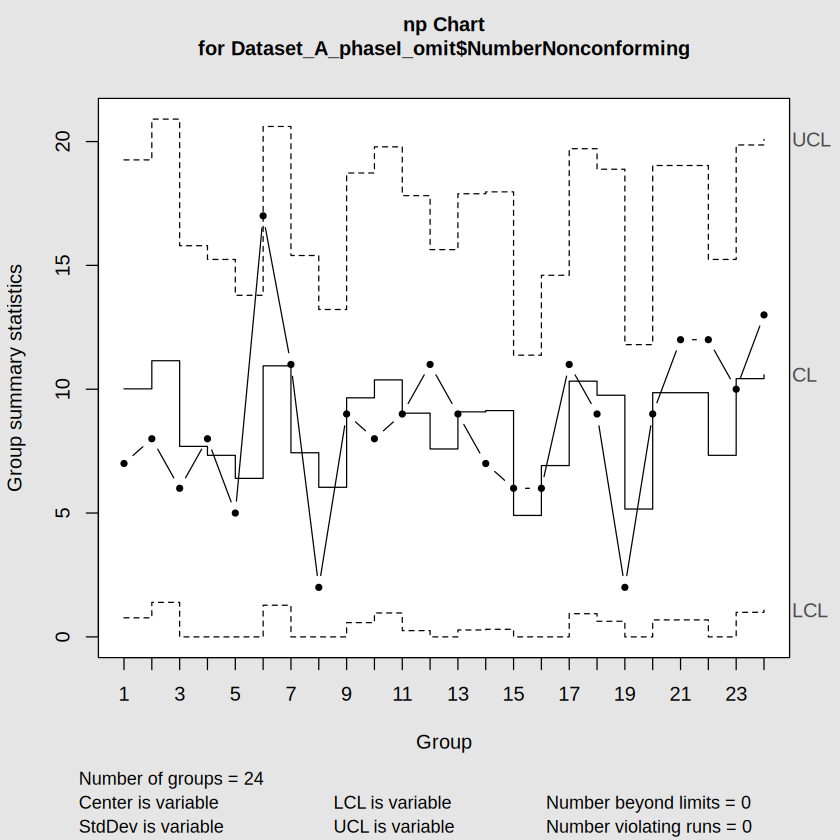

In [38]:
npchart_A_PhaseI_omit <- qcc(Dataset_A_phaseI_omit$`NumberNonconforming`,type="np",
                sizes=Dataset_A_phaseI_omit$`TotalComics`,
                plot=T)

The conclusion to remove week 14 is still the same between both charts. Both charts are now in control. The np chart is easier to explain to the distributor account representative because it shows actual counts of nonconforming comics rather than the p chart that is looking at proportion of damage. The p chart is better for our monitoring of the process because of the shipment sizes not being the same but would be harder to interpret for the distributer.

### Q6: Using your finalized Phase I estimate of $\bar{p}$, report the center line and control limits you will carry forward into Phase II.

In [32]:
## Q6 Code ##
pbar<-pchart_A_PhaseI_IC$center
pbar
pchart_A_PhaseI_IC$limits #these vary because sample size changes and wont be same wiht new phase II sample size


#going to calcualte the std from phase I pbar for phase II and use in qcc for limits
sqrt(pbar*(1-pbar))

[1] 0.05162095

,LCL,UCL
,0.003964205,0.09927769
,0.006456330,0.09678557
,0.000000000,0.10600006
,0.000000000,0.10732426
,0.000000000,0.11123030
,0.006032239,0.09720966
,0.000000000,0.10693608
,0.000000000,0.11298758
,0.003080429,0.10016147
,0.004801403,0.09844049


[1] 0.2212605

Variable sample sizes make the limits not be transferable to the new chart so I will calculate them manually by using pbar from phase I data and standard deviation from pbar.

## Improve

### Q7: After seeing your Phase I results, Ravi calls the distributor, who agrees to add cardboard stiffeners to every shipping box going forward. Briefly explain why it would not be appropriate to use your *original* (uncleaned) Phase I control limits, rather than the finalized limits from Q6, to judge whether this packaging fix actually worked.

The original uncleaned data had week 14 which was identified as an out of control point because of potential special case cause of variation from shipping handling to even unboxing. It would cuase the controls and center line to not represent the process in a normal stable baseline. This will allow us to evaluate the cardboard stiffeners being added in a more reliabel way.


## Control

### Q8: Read the Phase II Shipment Condition data into R. Using your finalized Phase I center line and control limits from Q6, construct the Phase II $p$ chart. Do any weeks plot outside the control limits? Does this support the conclusion that the packaging fix worked?

[1] 0.2212605

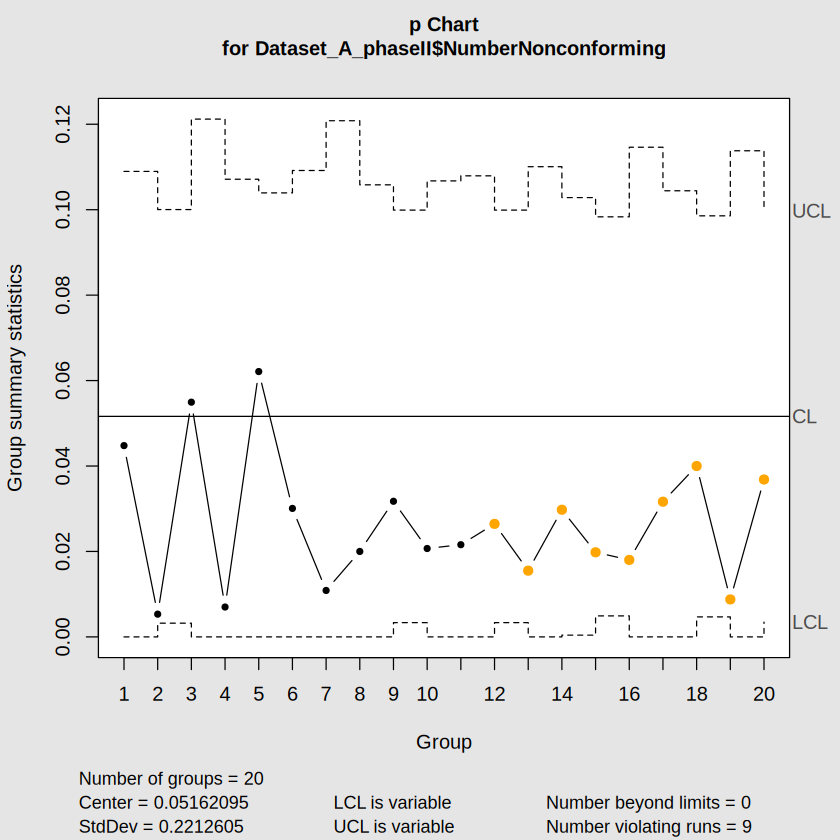

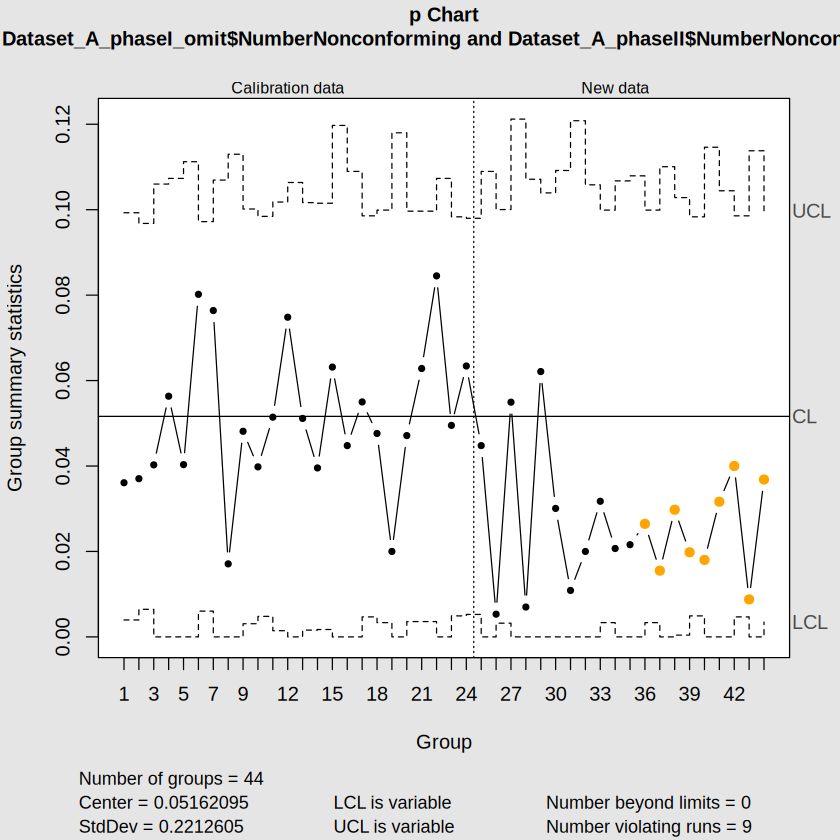

In [36]:
## Q8 Code ##
Dataset_A_phaseII<-read_xlsx("RavisComics_ShipmentCondition_PhaseII.xlsx")

#going to calcualte the std from phase I pbar for phase II
sqrt(pbar*(1-pbar))

pchart_A_PhaseII<-qcc(Dataset_A_phaseII$NumberNonconforming,
                     sizes=Dataset_A_phaseII$TotalComics,
                     type = 'p',
                     center = pbar,
                     std.dev = sqrt(pbar*(1-pbar)),
                     nsigmas = 3)

# I like this chart better to see phase I and phase II side by side for trends
p_allphases <- qcc(
  Dataset_A_phaseI_omit$NumberNonconforming,
  sizes = Dataset_A_phaseI_omit$TotalComics,
  type = "p",
  newdata = Dataset_A_phaseII$NumberNonconforming,
  newsizes = Dataset_A_phaseII$TotalComics
)

No weeks plot outside the control limits but there are 9 violating runs and you can see in the second plot with both phase I and phase II data side by side. This is showing that the phase II data is plotting mostly below the center line from phase I control. The line is showing a downward trend below the center line showing that the cardboard backing in packaging are appearing to reduce damage in shipment.

### Q9: Repeat Q8 using an $np$ chart instead. Is your conclusion consistent with Q8?

[1] 10.014464 11.150125  7.691521  7.330175  6.400998 10.943641  7.433416
 [8]  6.039651  9.653117 10.375810  9.033666  7.588279  9.085287  9.136908
[15]  4.903990  6.917207 10.324190  9.756359  5.162095  9.859601  9.859601
[22]  7.330175 10.427431 10.582294

Warning message in center/sizes:
“longer object length is not a multiple of shorter object length”
Warning message in center - tol:
“longer object length is not a multiple of shorter object length”
Warning message in center + tol:
“longer object length is not a multiple of shorter object length”
Warning message in pmin(center + tol, sizes):
“an argument will be fractionally recycled”
Warning message in statistics > ucl:
“longer object length is not a multiple of shorter object length”
Warning message in statistics < lcl:
“longer object length is not a multiple of shorter object length”
Warning message in statistics - center:
“longer object length is not a multiple of shorter object length”
Warning message in center/sizes:
“longer object length is not a multiple of shorter object length”
Warning message in center - tol:
“longer object length is not a multiple of shorter object length”
Warning message in center + tol:
“longer object length is not a multiple of shorter object length”
Warn

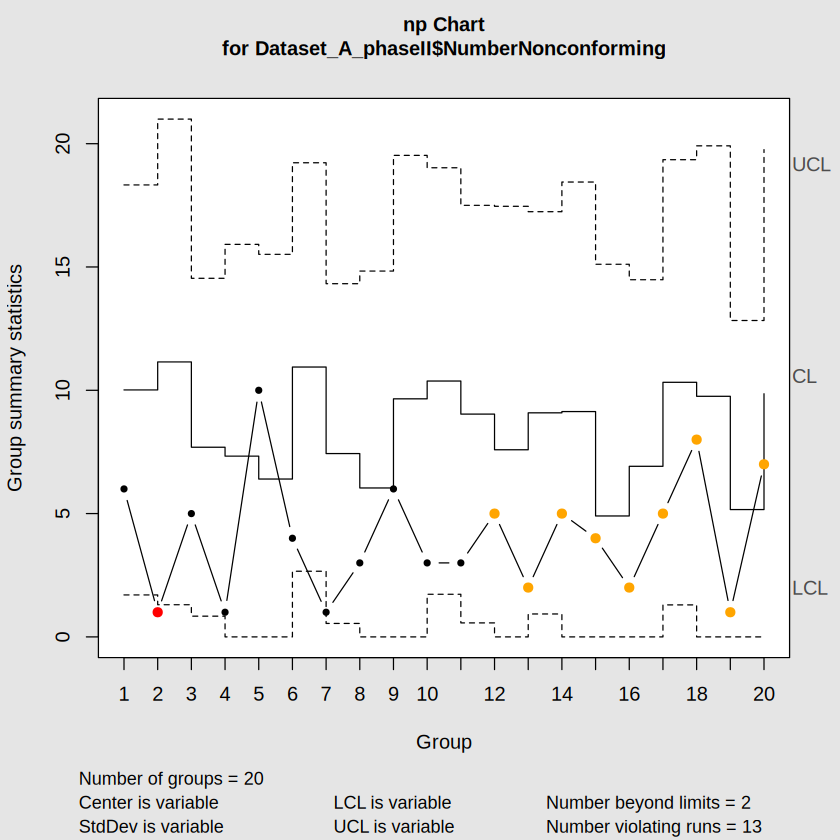

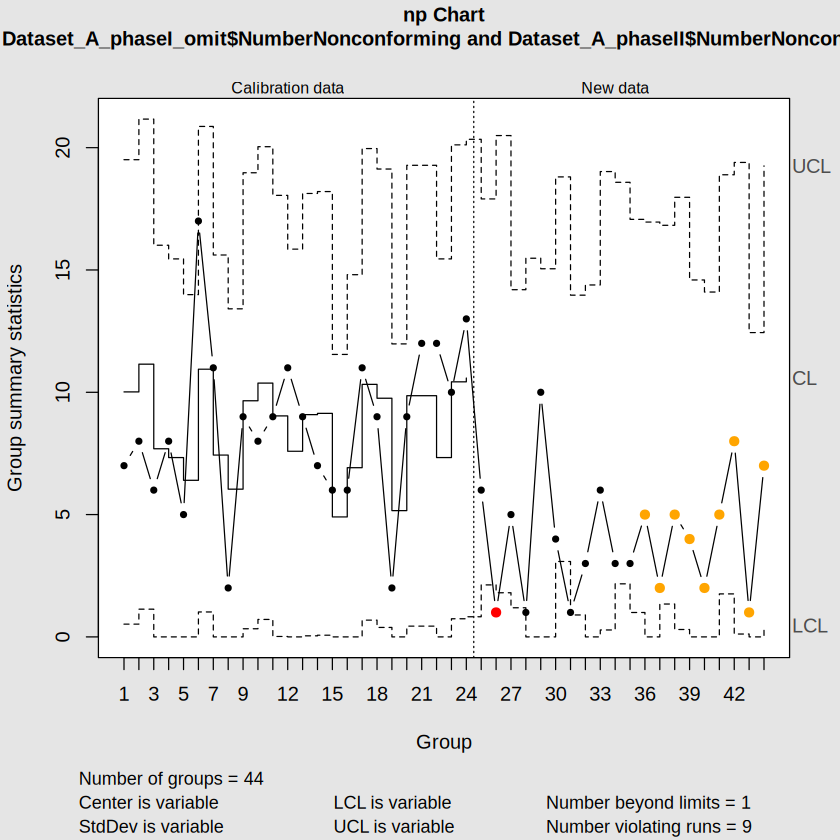

In [55]:
## Q9 Code ##
n<-Dataset_A_phaseI_omit$TotalComics
np_bar<-pbar*n
np_bar
np_std<-sqrt(np_bar*(1-pbar))

npchart_A_PhaseII<-qcc(Dataset_A_phaseII$NumberNonconforming,
                     sizes=Dataset_A_phaseII$TotalComics,
                     type = 'np',
                     center = np_bar,
                     std.dev = np_std,
                     nsigmas = 3)

np_allphases <- qcc(
  Dataset_A_phaseI_omit$NumberNonconforming,
  sizes = Dataset_A_phaseI_omit$TotalComics,
  type = "np",
  newdata = Dataset_A_phaseII$NumberNonconforming,
  newsizes = Dataset_A_phaseII$TotalComics
)

There appears to be a point out of control Week 2 of phase II data but it is out of control in the correct direction of being less damage than the phase I control so it does agree without conclusion from the p chart.

### Q10: Read the New-Release Defect Counts data (Dataset B) into R. Construct a $c$ chart. Does the chart show evidence of statistical control? If not, identify the out-of-control week(s) by number and provide a contextual explanation as to why these OOC point(s) may have been observed, omit them, and replot the chart until statistical control is observed.

Rows: 25
Columns: 3
$ Week            <dbl> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16,…
$ BoxesInspected  <dbl> 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, …
$ NumberOfDefects <dbl> 14, 8, 9, 8, 11, 10, 10, 52, 11, 10, 10, 12, 6, 11, 6,…


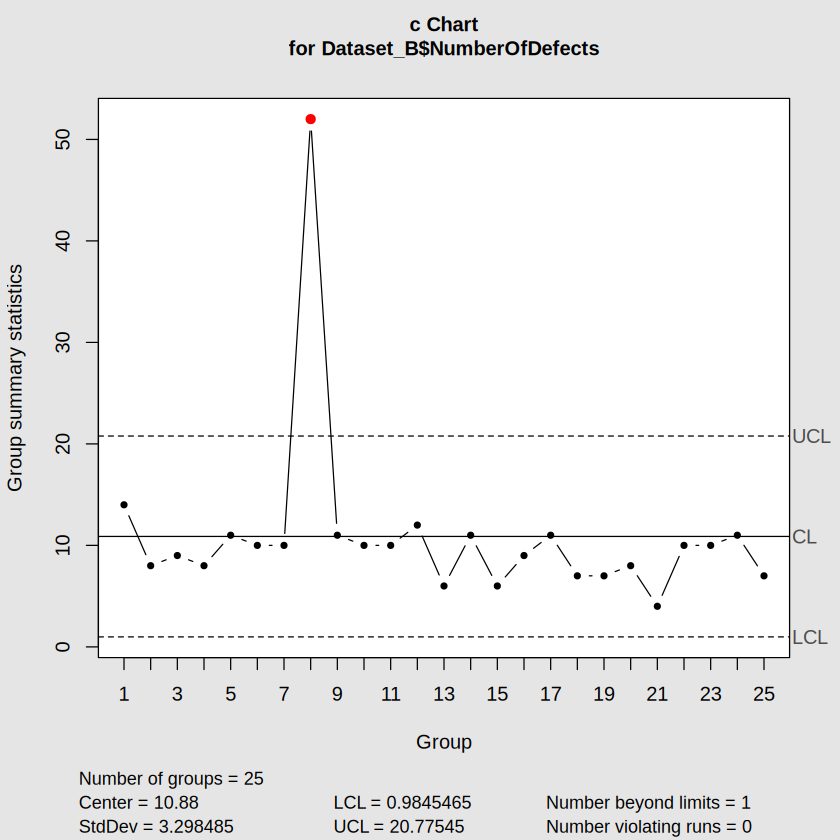

In [57]:
## Q10 Code ##
Dataset_B<-read_xlsx("RavisComics_NewReleaseDefectCounts.xlsx")

glimpse(Dataset_B)

c_DatasetB<- qcc(Dataset_B$`NumberOfDefects`,
                          type="c",plot=T)

Week 8 is OOC point and could be due to an unboxing or handling error with that many defects found per inspection of the 5 boxes that week, that specific shipment could have had a different carrier who did not handle it appropriately. We will remove the point and replot.

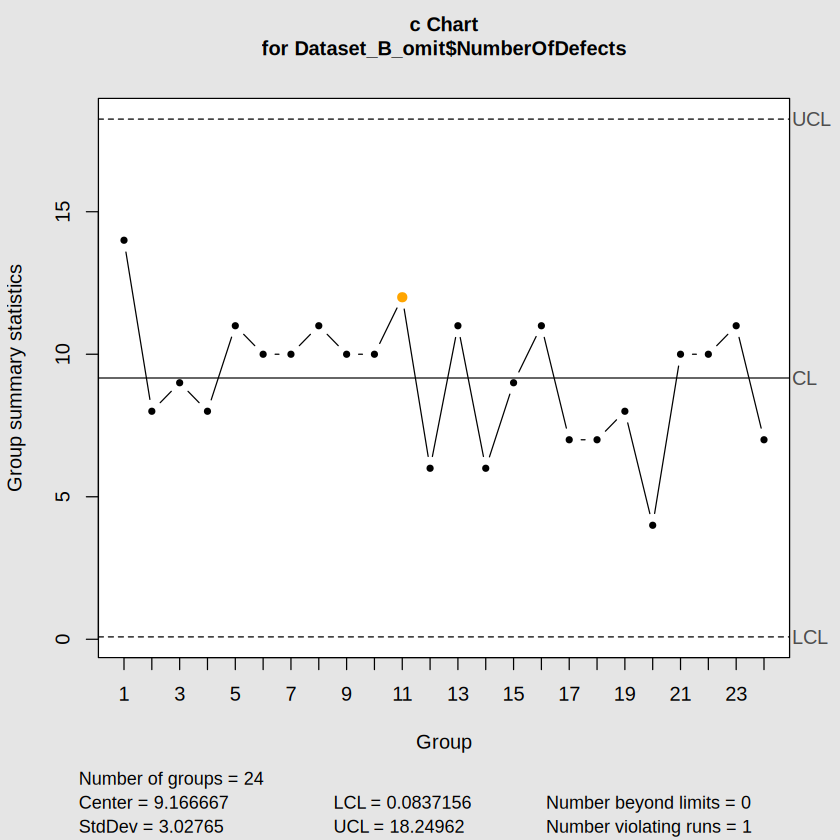

In [60]:
Dataset_B_omit<-Dataset_B[-8,]

c_DatasetB_omit<- qcc(Dataset_B_omit$`NumberOfDefects`,
                          type="c",plot=T)

The chart now appears to be in control.

### Q11: Using your finalized $c$ chart, report $\bar{c}$ and the control limits. In 1-2 sentences, explain what this chart tells Ravi that the Q4-Q9 pass/fail analysis could not.

In [62]:
## Q11 Code ##
cbar<-c_DatasetB_omit$center
cbar
c_DatasetB_omit$limits
uclc <- c_DatasetB_omit$limits[2]
lclc <- c_DatasetB_omit$limits[1]

[1] 9.166667

,LCL,UCL
,0.0837156,18.24962


Th c chart allows Ravi to see the number of individual defects that are on a comic rather than just if a comic is defective or not. This can help us understand the extent of damage rather than a simple pass/fail.

### Q12: Read the Back-Issue Defect Counts data (Dataset C) into R. Construct a $u$ chart. Does the chart show evidence of statistical control? If not, identify the out-of-control week(s) by number and provide a contextual explanation as to why these OOC point(s) may have been observed, omit them, and replot the chart until statistical control is observed.

Rows: 25
Columns: 3
$ Week            <dbl> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16,…
$ BoxesInspected  <dbl> 8, 10, 5, 3, 4, 5, 8, 2, 9, 8, 9, 10, 3, 4, 9, 2, 6, 8…
$ NumberOfDefects <dbl> 9, 11, 0, 2, 2, 9, 5, 1, 14, 5, 6, 11, 6, 7, 16, 3, 34…


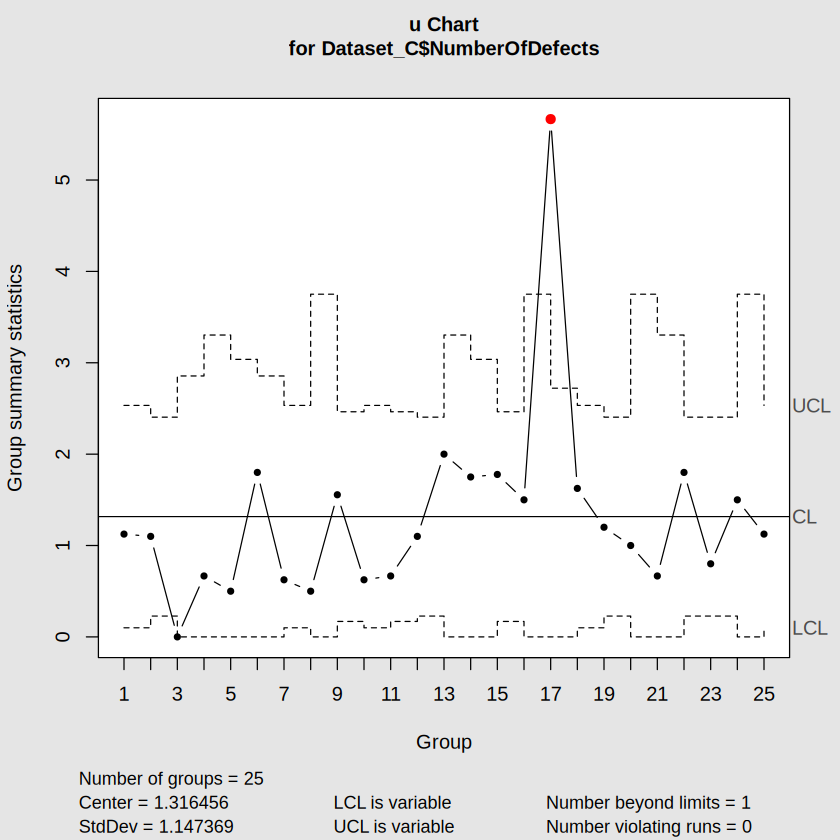

In [65]:
## Q12 Code ##
Dataset_C<-read_xlsx("RavisComics_BackIssueDefectCounts.xlsx")

glimpse(Dataset_C)

u_DatasetC<- qcc(Dataset_C$`NumberOfDefects`,
                 size = Dataset_C$`BoxesInspected`,
                          type="u",plot=T)

Week 17 was identified to be an OOC this could be that there were issues that week with the carrier, or handling of the comics as they were unboxed. We will remove the point and replot the chart.

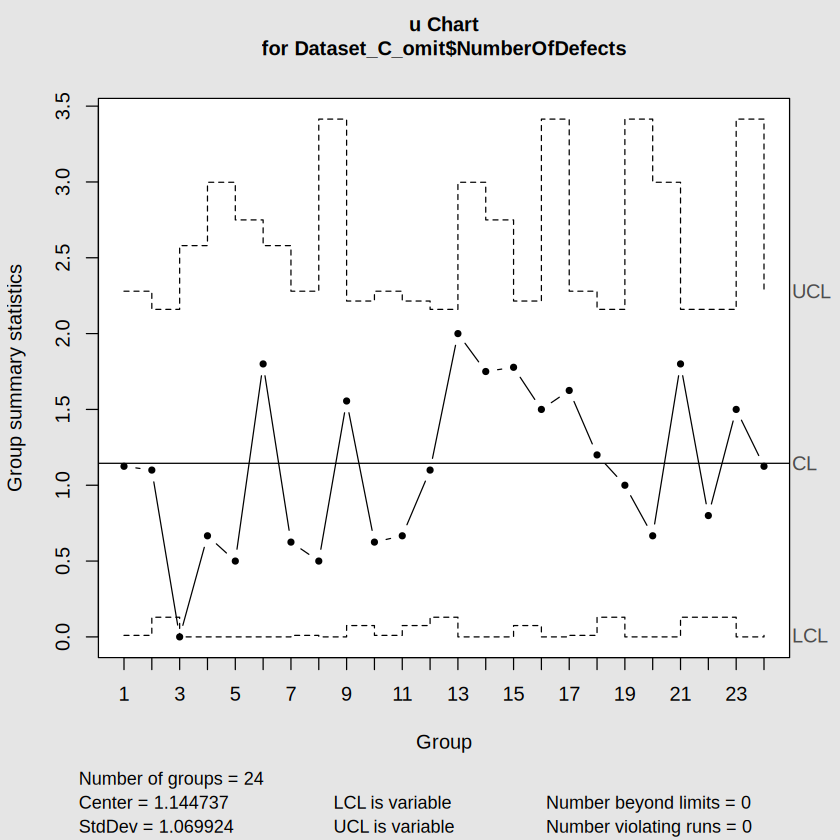

In [66]:
Dataset_C_omit<-Dataset_C[-17,]

u_DatasetC_omit<- qcc(Dataset_C_omit$`NumberOfDefects`,
                      size = Dataset_C_omit$`BoxesInspected`,
                          type="u",plot=T)

The plot appears to be in statistical control now.

### Q13: Suppose you tried to build a $c$ chart on the Back-Issue Defect Counts data instead of a $u$ chart. Why would this not be an appropriate choice, given how the data were collected?

The c chart would not be a good choice because the number of back issue boxes inspected (sample) varied. The u chart is the better option because it monitors defects while accounting for weekly sample size changes allowing for a better comparison because if you have 2 defects in 10 box inspections and 2 defects in 2 box inspections you would want this difference to be correctly monitored.

### Q14: Provide an overview of your results that Ravi can use the next time he calls the distributor's account representative. Citing specific evidence from your $p$/$np$ analysis **and** your $c$/$u$ analysis, which parts of the damage problem look like they're the distributor's responsibility, and which parts (if any) look more like an internal, in-shop handling issue?

The p and np charts initally show a issue with comic books having nonconformity, out of control week data was removed. With the addition of phase II data after the distributor then added cardboard backing when they shiped the comics we saw the number and pass/fail proportions fall indicating that there were less nonconformed or defective comics after the change.

The c chart for new-realsed comics showed 9.2% defects per weekly inspection of the fixed sample of 5 boxes and the u chart of the back issue comics showed average of 1.1% defects per boxes of the varied sample sizes. These suggest that there is no defined issue with internal handling of the comics.

The shift we saw in defects after the phase II data of the distributor adding cardboard shows that the defective comics appear to be reducing after the change. The internal handling should continue to be looked at and identifying the location or areas of defects could be helpful in distinguishing a shipping issue and a internal handling issue. For example if all defects from distribution occured to the edges of the comics but the covers were cratched in the back issues the different locations of the defects could be due to different reasons. Overall I believe it is a distributor issue but as I said I would further look into the difference between defects marked when shelved and defects marked when sold to identify potential internal handling issues.